In [ ]:
# Purpose:
#   Construct and validate an NHB-BC “upregulated” pseudobulk signature, then
#   characterize its biology and per-celltype expression.
#
# Steps
#   A) Define an NHB-BC Up gene list from pseudobulk DE results (BC stage, NHB vs NHW),
#      using a donor-level Mann–Whitney screen on normalized expression to ensure
#      NHB > NHW in BC.
#   B) Annotate genes (protein-coding vs others) via mygene and write GMT signatures.
#   C) Visualize:
#        1) Per-gene boxplots across race-stage groups (HRL/DCIS/BC × NHW/NHB)
#        2) Stacked bar: how many signature genes are DE (up) per celltype × disease stage
#        3) Enrichr pathway enrichment for the signature gene list + barplot top terms
#        4) ssGSEA score distributions across race-stage per celltype (boxplots)

# Header

In [1]:
from utils import *

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import anndata as ad
import math
from collections import Counter
import pickle as pkl
import os 
from scipy.stats import linregress
import seaborn as sns

import gseapy as gp
from gseapy import barplot, dotplot
import mygene

In [2]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none', # Keeps text as font
    
    'font.size': 6,  # 5–7 pt as per guidelines
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'ytick.labelsize': 5,

    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    
    'figure.dpi': 600
})

plt.rcParams['axes.grid'] = False   # <--- turn off all grids globally
sns.set_style("white")              # <--- turn off seaborn grids

In [3]:
def read_gmt(file_path):
    gene_sets = {}
    with open(file_path, 'r') as f:
        for line in f:
            entries = line.strip().split('\t')
            gene_set_name = entries[0]
            description = entries[1]
            genes = entries[2:]
            gene_sets[gene_set_name] = {
                'description': description,
                'genes': genes
            }
    return gene_sets

In [4]:
os.chdir('../')

In [5]:
cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}
major_celltype_palette = {
    'B':    '#3072C4',
    'T':    '#EF763F',
    'DC':   '#35A293',
    'Mono': '#B3813E',
    'NK':   '#7D4C99'
}

In [6]:
palette_meta = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830',

    'Diabetes':'navy',
    'Obesity':'salmon'
}


# Load data

In [7]:
dat = ad.read_h5ad('data/03_cleandata/ft_all.h5ad')
print(len(dat.obs['dataset_name'].unique()))
dat

55


AnnData object with n_obs × n_vars = 434565 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3'
    var: 'vf_vst_counts.Pool137_10_mean', 'vf_vst_counts.Pool137_10_variance', 'vf_vst_counts.Pool137_10_variance.expected', 'vf_vst_counts.Pool137_10_variance.standardized', 'vf_vst_counts.Pool137_10_variable', 'vf_vst_counts.Pool137_10_rank', 'vf_vst_counts.Pool137_11_mean', 'vf_vst_counts.Pool137_11_variance', 'vf_vst_counts.Pool137_11_variance.expected', 'vf_vst_counts.Pool137_11_variance.standardized', 'vf_vst_counts.Pool137_11_variable', 'vf_vst_counts.Pool137

In [8]:
meta = pd.read_csv('data/01_meta/meta_pt.csv', 
                   index_col = 'dataset_name')

meta.index = [x.replace('_','-') for x in meta.index]

meta['race-stage'] = meta['race'].astype(str) + '-' + meta['group'].astype(str)

meta['race-stage'] = pd.Categorical(
    meta['race-stage'],
    categories=['NHW-HRL','NHB-HRL',  'NHW-DCIS','NHB-DCIS',  'NHW-BC','NHB-BC'],
    ordered=True
    )


meta

,sampleid,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
Pool137-7,9-D,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS
Pool137-12,30-D,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
Pool137-18,36-D,1,93,DCIS,NHB,39.0,N,N,NHB-DCIS
Pool137-20,119-D,1,95,DCIS,NHB,80.0,N,N,NHB-DCIS
Pool137-24,28-D,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
Pool137-27,53-D,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
Pool137-30,77-D,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
Pool138-6,31-D,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
Pool137-6,6-H,1,94,HRL,NHW,71.1,N,Y,NHW-HRL
Pool137-10,1-H,1,88,HRL,NHW,62.3,N,N,NHW-HRL


In [9]:
expr = pd.read_csv(
    'data/06_pb/pb_donor_normalizedexpression.csv',
    index_col=0
)

print(expr.shape)

expr

(27879, 55)


,Pool137-10,Pool137-11,Pool137-12,Pool137-14,Pool137-15,Pool137-16,Pool137-17,Pool137-18,Pool137-19,Pool137-20,...,Pool138-26,Pool138-27,Pool138-29,Pool138-3,Pool138-4,Pool138-5,Pool138-6,Pool138-7,Pool138-8,Pool138-9
AL627309.1,0.002970,0.004021,0.005273,0.002441,0.002460,0.004293,0.003563,0.005085,0.002822,0.000000,...,0.002078,0.003163,0.002261,0.001021,0.001734,0.001724,0.001117,0.001690,0.002495,0.002138
AL627309.5,0.013665,0.008026,0.027806,0.003963,0.011752,0.013249,0.007113,0.013418,0.013196,0.028958,...,0.025166,0.018521,0.009015,0.012181,0.006671,0.009159,0.018454,0.007462,0.007775,0.004004
LINC01409,0.075192,0.075008,0.084985,0.069608,0.095301,0.068181,0.085470,0.086154,0.058724,0.106176,...,0.197999,0.130235,0.162613,0.073807,0.068495,0.065922,0.068038,0.052022,0.067309,0.058190
LINC01128,0.085145,0.111464,0.087141,0.091866,0.104217,0.126716,0.098261,0.079114,0.098179,0.119300,...,0.199705,0.189106,0.217276,0.114397,0.097919,0.090123,0.107614,0.101908,0.086677,0.083359
LINC00115,0.029676,0.023624,0.022651,0.024739,0.031515,0.030924,0.024428,0.020186,0.025394,0.032520,...,0.075604,0.057562,0.068250,0.027202,0.024728,0.030301,0.032256,0.027878,0.017640,0.019076
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AC104758.2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000802
AC015660.3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000802
ZG16,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001069
AP001434.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000802


In [10]:
deg = pd.read_csv(
    'data/07_pb_deg_fgsea/DEG_NHBvsNHW_celltypelevel3_EachDiseaseStage.csv',
    index_col = 0
              )

deg

,gene,logFC,logCPM,LR,PValue,FDR,group,celltype
1,SNHG5,-1.250187,7.089642,3.082271e+01,2.827104e-08,0.000278,HRL,Naive B
2,MT-ND3,-0.870828,10.687962,2.584486e+01,3.699882e-07,0.001821,HRL,Naive B
3,LINC01505,2.094198,4.123173,2.337949e+01,1.329889e-06,0.004047,HRL,Naive B
4,MTRNR2L8,-6.797409,10.016917,2.297050e+01,1.645064e-06,0.004047,HRL,Naive B
5,PSPH,1.936161,3.095421,2.251051e+01,2.089965e-06,0.004113,HRL,Naive B
...,...,...,...,...,...,...,...,...
488345,RPL4,0.001116,10.188501,4.289893e-05,9.947741e-01,0.998097,BC,Proliferating NK
488346,TSPO,-0.001668,8.473411,2.815756e-05,9.957661e-01,0.998097,BC,Proliferating NK
488347,GLS,0.002892,8.155241,1.905838e-05,9.965168e-01,0.998097,BC,Proliferating NK
488348,FYN,0.001219,9.708173,1.201948e-05,9.972338e-01,0.998097,BC,Proliferating NK


# DEGs

In [8]:
deg['celltype'].unique()

array(['Naive B', 'Mature B', 'Memory B', 'Plasmablast', 'Naive CD4T',
       'Central Memory CD4T', 'Effector Memory CD4T', 'Cytotoxic CD4T',
       'Treg', 'Naive CD8T', 'Central Memory CD8T',
       'Effector Memory CD8T', 'Double Negative T', 'γδ T', 'MAIT',
       'cDC1', 'cDC2', 'pDC', 'Classical Monocyte',
       'Intermediate Monocyte', 'Nonclassical Monocyte',
       'Cytotoxic Monocyte', 'CD56-dim NK', 'CD56-bright NK',
       'Proliferating NK'], dtype=object)

In [32]:
# up genes in selected cell types

celltype_sel = [
    'Naive B', 'Mature B', 'Memory B', 'Plasmablast', 
    'Naive CD4T','Central Memory CD4T', 'Effector Memory CD4T', 'Cytotoxic CD4T','Treg',
    'cDC1', 'cDC2', 'pDC',
    'Intermediate Monocyte', 'Nonclassical Monocyte','Cytotoxic Monocyte'
]

deg_ft = deg[
    (deg['group'].isin(['BC'])) &
    (deg['FDR'] < 0.05) &
    (deg['celltype'].isin(celltype_sel))
    ]


goi_init = deg_ft['gene'].unique()
len(goi_init)

541

Filter: for each of these genes in BC, NHW vs NHB, by mannwhitenyu, record P, do FDR correction

In [33]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import pandas as pd
import numpy as np

# Filter for BC group
bc_mask = meta['group'] == 'BC'
bc_meta = meta.loc[bc_mask]
bc_expr = expr.loc[goi_init, bc_mask]

pvals = []
mean1 = []
mean2 = []
ratio = []

for gene in goi_init:
    x = bc_expr.loc[gene, bc_meta['race'] == 'NHW']
    y = bc_expr.loc[gene, bc_meta['race'] == 'NHB']
    # If either group has no variance or not enough samples, skip
    if (len(x) < 2) or (len(y) < 2):
        pvals.append(np.nan)
        mean1.append(np.nan)
        mean2.append(np.nan)
        ratio.append(np.nan)
        continue
    stat, p = mannwhitneyu(x, y, alternative='two-sided')
    pvals.append(p)
    m1 = np.mean(x)
    m2 = np.mean(y)
    mean1.append(m1)
    mean2.append(m2)
    # Avoid division by zero
    ratio.append(m2/m1 if m1 != 0 else np.nan)

# FDR correction
pvals = np.array(pvals)
fdr_pvals = multipletests(pvals, method='fdr_bh')[1]

# Results DataFrame
results_df = pd.DataFrame({
    'gene': goi_init,
    'pval': pvals,
    'fdr': fdr_pvals,
    'mean_NHW': mean1,
    'mean_NHB': mean2,
    'NHB/NHW': ratio
}).sort_values('fdr')

In [34]:
results_dfsel = results_df[
    (results_df['fdr'] < 0.05) &
    (results_df['NHB/NHW'] > 1)
    ]
print(results_dfsel.shape)
results_dfsel

gois_up = results_dfsel['gene'].tolist()
print(len(gois_up))


(37, 6)
37


In [35]:
results_dfsel = results_df[
    (results_df['fdr'] < 0.05) &
    (results_df['NHB/NHW'] < 1)
    ]

print(results_dfsel.shape)
results_dfsel

gois_dn = results_dfsel['gene'].tolist()
print(len(gois_dn))

(57, 6)
57


In [36]:
write_gmt({'IMM-POP Up':gois_up,# all 
          'IMM-POP Dn': gois_dn},# protein-coding only
          'data/08_signature/IMMPOP.gmt')

finished writing 2 gene sets to data/08_signature/IMMPOP.gmt


# Signature gene expression

In [7]:
gset = read_gmt(
    'data/08_signature/IMMPOP.gmt'
)

gset

{'IMM-POP Up': {'description': 'http',
  'genes': ['IGKV1D-17',
   'PSPH',
   'GATD3A',
   'LY6E-DT',
   'LRPAP1',
   'PAIP2',
   'LMNA',
   'MTHFD2L',
   'LAPTM4B',
   'LINC00886',
   'KLF3',
   'SLC9A3',
   'KLF8',
   'LRG1',
   'SNHG15',
   'CLCF1',
   'HRK',
   'TMEM123',
   'PWP2',
   'LIPC',
   'C2CD4B',
   'TIPARP',
   'ZNF394',
   'RNF11',
   'NIPBL-DT',
   'MBD2',
   'SMAD1',
   'FAM3A',
   'LINC02384',
   'AC240274.1',
   'LINC00865',
   'BFSP2',
   'ABHD12',
   'CHMP4B',
   'MAFF',
   'HES4',
   'NEBL']},
 'IMM-POP Dn': {'description': 'http',
  'genes': ['BRAT1',
   'COG4',
   'GTF2F1',
   'AC011472.2',
   'ARPIN',
   'TMEM187',
   'AL355075.4',
   'MT-ND1',
   'FP565260.1',
   'HEIH',
   'DBP',
   'ENGASE',
   'GAS8',
   'NDUFAF8',
   'RPP25L',
   'AC007368.1',
   'HDHD3',
   'HKDC1',
   'TRAF3IP3',
   'CCDC137',
   'LINC02256',
   'AL592183.1',
   'RABEPK',
   'ST6GALNAC1',
   'PRRT1',
   'C11orf68',
   'AC008083.2',
   'AC099063.4',
   'GNB1L',
   'IMP3',
   'GATD3B',
  

In [8]:
gois_up = gset['IMM-POP Up']['genes']
gois_dn = gset['IMM-POP Dn']['genes']

In [69]:
meta = pd.read_csv('data/01_meta/meta_pt.csv', 
                   index_col = 'dataset_name')

meta.index = [x.replace('_','-') for x in meta.index]

meta['race-stage'] = meta['race'].astype(str) + '-' + meta['group'].astype(str)

meta['race-stage'] = pd.Categorical(
    meta['race-stage'],
    categories=['NHW-HRL','NHB-HRL',  'NHW-DCIS','NHB-DCIS',  'NHW-BC','NHB-BC'],
    ordered=True
    )


meta

,sampleid,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
Pool137-7,9-D,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS
Pool137-12,30-D,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
Pool137-18,36-D,1,93,DCIS,NHB,39.0,N,N,NHB-DCIS
Pool137-20,119-D,1,95,DCIS,NHB,80.0,N,N,NHB-DCIS
Pool137-24,28-D,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
Pool137-27,53-D,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
Pool137-30,77-D,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
Pool138-6,31-D,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
Pool137-6,6-H,1,94,HRL,NHW,71.1,N,Y,NHW-HRL
Pool137-10,1-H,1,88,HRL,NHW,62.3,N,N,NHW-HRL


In [68]:
expr = pd.read_csv(
    'data/06_pb/pb_donor_normalizedexpression.csv',
    index_col=0
)

print(expr.shape)

expr

(27879, 55)


,Pool137-10,Pool137-11,Pool137-12,Pool137-14,Pool137-15,Pool137-16,Pool137-17,Pool137-18,Pool137-19,Pool137-20,...,Pool138-26,Pool138-27,Pool138-29,Pool138-3,Pool138-4,Pool138-5,Pool138-6,Pool138-7,Pool138-8,Pool138-9
AL627309.1,0.002970,0.004021,0.005273,0.002441,0.002460,0.004293,0.003563,0.005085,0.002822,0.000000,...,0.002078,0.003163,0.002261,0.001021,0.001734,0.001724,0.001117,0.001690,0.002495,0.002138
AL627309.5,0.013665,0.008026,0.027806,0.003963,0.011752,0.013249,0.007113,0.013418,0.013196,0.028958,...,0.025166,0.018521,0.009015,0.012181,0.006671,0.009159,0.018454,0.007462,0.007775,0.004004
LINC01409,0.075192,0.075008,0.084985,0.069608,0.095301,0.068181,0.085470,0.086154,0.058724,0.106176,...,0.197999,0.130235,0.162613,0.073807,0.068495,0.065922,0.068038,0.052022,0.067309,0.058190
LINC01128,0.085145,0.111464,0.087141,0.091866,0.104217,0.126716,0.098261,0.079114,0.098179,0.119300,...,0.199705,0.189106,0.217276,0.114397,0.097919,0.090123,0.107614,0.101908,0.086677,0.083359
LINC00115,0.029676,0.023624,0.022651,0.024739,0.031515,0.030924,0.024428,0.020186,0.025394,0.032520,...,0.075604,0.057562,0.068250,0.027202,0.024728,0.030301,0.032256,0.027878,0.017640,0.019076
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AC104758.2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000802
AC015660.3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000802
ZG16,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001069
AP001434.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000802


In [70]:
expr_bc = expr.loc[
    :,meta[meta['group']=='BC'].index
]
expr_bc

,Pool137-11,Pool137-15,Pool137-16,Pool137-17,Pool137-19,Pool137-23,Pool137-28,Pool137-31,Pool138-3,Pool138-5,...,Pool138-21,Pool138-22,Pool138-23,Pool138-24,Pool138-25,Pool138-27,Pool138-29,Pool138-17,Pool138-20,Pool138-26
AL627309.1,0.004021,0.002460,0.004293,0.003563,0.002822,0.002863,0.001778,0.003941,0.001021,0.001724,...,0.001183,0.001702,0.003700,0.000979,0.001139,0.003163,0.002261,0.000596,0.003508,0.002078
AL627309.5,0.008026,0.011752,0.013249,0.007113,0.013196,0.018749,0.012628,0.021212,0.012181,0.009159,...,0.003938,0.003826,0.011060,0.004887,0.007571,0.018521,0.009015,0.000596,0.007005,0.025166
LINC01409,0.075008,0.095301,0.068181,0.085470,0.058724,0.099802,0.083116,0.050601,0.073807,0.065922,...,0.051899,0.061133,0.061114,0.050935,0.053275,0.130235,0.162613,0.063512,0.051376,0.197999
LINC01128,0.111464,0.104217,0.126716,0.098261,0.098179,0.121367,0.122781,0.105133,0.114397,0.090123,...,0.098023,0.084890,0.087499,0.108818,0.107956,0.189106,0.217276,0.065747,0.119138,0.199705
LINC00115,0.023624,0.031515,0.030924,0.024428,0.025394,0.045408,0.023858,0.025345,0.027202,0.030301,...,0.029165,0.029794,0.031024,0.026110,0.026622,0.057562,0.068250,0.021233,0.023160,0.075604
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AC104758.2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
AC015660.3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ZG16,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
AP001434.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [71]:
dfp = expr_bc.T.join(meta[['race','age']], how='left')
dfp

,AL627309.1,AL627309.5,LINC01409,LINC01128,LINC00115,FAM41C,NOC2L,KLHL17,PLEKHN1,AL645608.7,...,ANKRD30A,LINC01068,AL135999.2,AC104758.2,AC015660.3,ZG16,AP001434.1,XAGE3,race,age
Pool137-11,0.004021,0.008026,0.075008,0.111464,0.023624,0.009357,0.291096,0.035878,0.010155,0.004021,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NHW,48.0
Pool137-15,0.002460,0.011752,0.095301,0.104217,0.031515,0.004914,0.282595,0.043847,0.010778,0.001477,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NHW,67.0
Pool137-16,0.004293,0.013249,0.068181,0.126716,0.030924,0.007714,0.278356,0.034671,0.011549,0.003007,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NHB,60.0
Pool137-17,0.003563,0.007113,0.085470,0.098261,0.024428,0.005847,0.295777,0.031123,0.020190,0.001528,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NHB,54.0
Pool137-19,0.002822,0.013196,0.058724,0.098179,0.025394,0.007322,0.294569,0.038534,0.008163,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NHW,79.0
Pool137-23,0.002863,0.018749,0.099802,0.121367,0.045408,0.008566,0.260556,0.039912,0.015366,0.001146,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NHW,66.0
Pool137-28,0.001778,0.012628,0.083116,0.122781,0.023858,0.007091,0.275307,0.030783,0.007344,0.001016,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NHW,63.0
Pool137-31,0.003941,0.021212,0.050601,0.105133,0.025345,0.005626,0.306815,0.034925,0.007587,0.003941,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NHB,47.0
Pool138-3,0.001021,0.012181,0.073807,0.114397,0.027202,0.007462,0.302855,0.047535,0.011172,0.001361,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NHW,46.0
Pool138-5,0.001724,0.009159,0.065922,0.090123,0.030301,0.006306,0.291273,0.045252,0.008589,0.003444,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NHW,67.0


/tmp/ipykernel_1100027/4030910560.py:41: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(data=dfp, x='race', y=gene, hue='race', color='k', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.941e-05 U_stat=8.500e+00


/tmp/ipykernel_1100027/4030910560.py:41: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(data=dfp, x='race', y=gene, hue='race', color='k', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.072e-05 U_stat=3.000e+00


/tmp/ipykernel_1100027/4030910560.py:41: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(data=dfp, x='race', y=gene, hue='race', color='k', alpha=0.4, linewidth=0, size=1, ax=ax)


...

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.338e-03 U_stat=2.900e+01


/tmp/ipykernel_1100027/4030910560.py:41: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(data=dfp, x='race', y=gene, hue='race', color='k', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.338e-03 U_stat=2.900e+01


/tmp/ipykernel_1100027/4030910560.py:41: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(data=dfp, x='race', y=gene, hue='race', color='k', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.655e-03 U_stat=2.900e+01


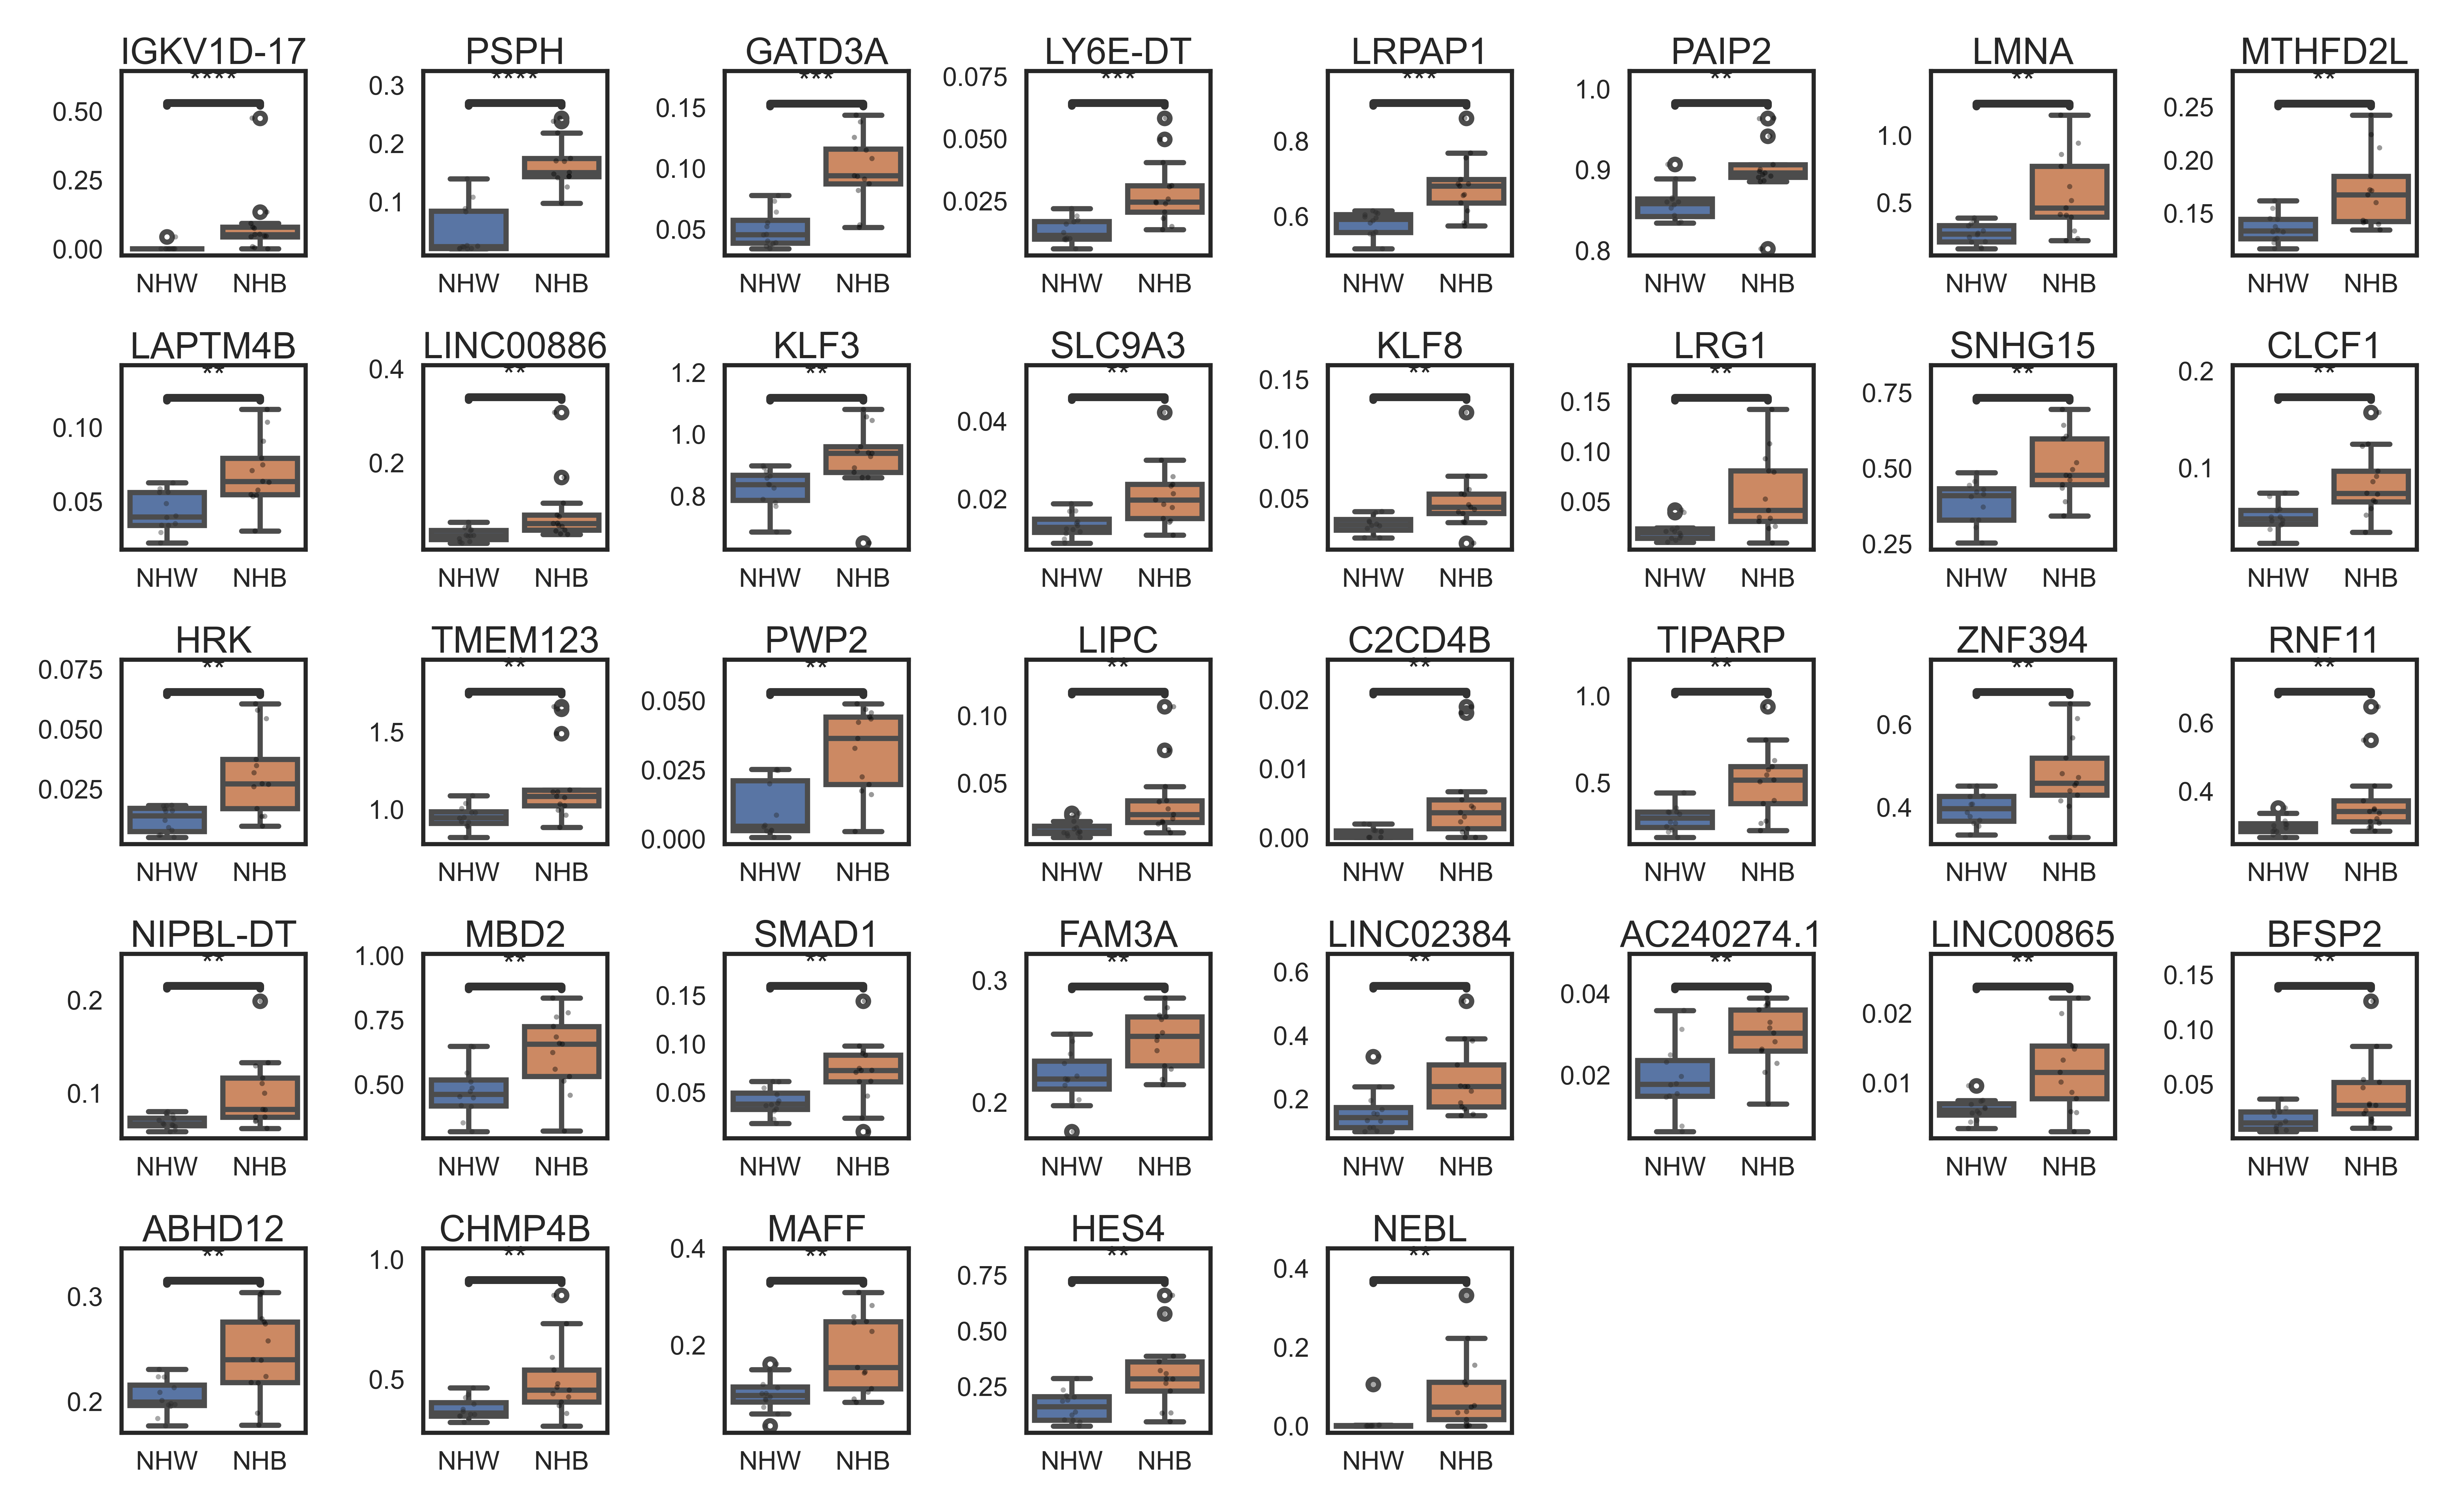

In [87]:
# all genes, regardless of protein coding
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from statannotations.Annotator import Annotator


rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none', # Keeps text as font
    
    'font.size': 6,  # 5–7 pt as per guidelines
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,

    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    
    'figure.dpi': 600
})


genes_plot = gois_up


palette = {'NHW': '#4C72B0', 'NHB': '#DD8452'} # sns, deep

n_genes = len(genes_plot)
ncol = 8
nrow = int(np.ceil(n_genes / ncol))

fig, axes = plt.subplots(nrow, ncol, figsize=(6.5, nrow*.8), sharey=False, sharex=False)
axes = axes.flatten()

for i, gene in enumerate(genes_plot):
    ax = axes[i]

    sns.boxplot(data=dfp, x='race', y=gene, hue='race', palette=palette, ax=ax, fliersize=2)
    sns.stripplot(data=dfp, x='race', y=gene, hue='race', color='k', alpha=0.4, linewidth=0, size=1, ax=ax)

    # Remove legend
    ax.legend_.remove() if ax.legend_ is not None else None

    # Mann-Whitney tests by group
    pairs = [('NHW', 'NHB')
]

    hue_plot_params = {'x': 'race', 'y': gene, 'data': dfp, 'palette': palette}
    annotator = Annotator(ax, pairs, **hue_plot_params)
    annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', comparisons_correction='fdr_bh')
    annotator.apply_and_annotate()

    ax.set_title(gene, pad=-2)
    ax.set_xlabel('')
    ax.set_ylabel('')
    # ax.set_xticklabels('')
    ax.tick_params(axis='x', labelrotation=0, pad=0)
    ax.tick_params(axis='y', pad=0)

# Remove empty axes
for j in range(i+1, nrow*ncol):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('plots/S8/boxplot_NHB-BC up genes.svg')
plt.show()

In [88]:
# all genes, regardless of protein coding
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from statannotations.Annotator import Annotator


rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none', # Keeps text as font
    
    'font.size': 6,  # 5–7 pt as per guidelines
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,

    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    
    'figure.dpi': 600
})


genes_plot = gois_dn


palette = {'NHW': '#4C72B0', 'NHB': '#DD8452'} # sns, deep

n_genes = len(genes_plot)
ncol = 8
nrow = int(np.ceil(n_genes / ncol))

fig, axes = plt.subplots(nrow, ncol, figsize=(6.5, nrow*.8), sharey=False, sharex=False)
axes = axes.flatten()

for i, gene in enumerate(genes_plot):
    ax = axes[i]

    sns.boxplot(data=dfp, x='race', y=gene, hue='race', palette=palette, ax=ax, fliersize=2)
    sns.stripplot(data=dfp, x='race', y=gene, hue='race', color='k', alpha=0.4, linewidth=0, size=1, ax=ax)

    # Remove legend
    ax.legend_.remove() if ax.legend_ is not None else None

    # Mann-Whitney tests by group
    pairs = [('NHW', 'NHB')
]

    hue_plot_params = {'x': 'race', 'y': gene, 'data': dfp, 'palette': palette}
    annotator = Annotator(ax, pairs, **hue_plot_params)
    annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', comparisons_correction='fdr_bh')
    annotator.apply_and_annotate()

    ax.set_title(gene, pad=-2)
    ax.set_xlabel('')
    ax.set_ylabel('')
    # ax.set_xticklabels('')
    ax.tick_params(axis='x', labelrotation=0, pad=0)
    ax.tick_params(axis='y', pad=0)

# Remove empty axes
for j in range(i+1, nrow*ncol):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('plots/S8/boxplot_NHB-BC dn genes.svg')
plt.show()

/tmp/ipykernel_1100027/2242969387.py:41: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(data=dfp, x='race', y=gene, hue='race', color='k', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.493e-05 U_stat=1.560e+02


/tmp/ipykernel_1100027/2242969387.py:41: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(data=dfp, x='race', y=gene, hue='race', color='k', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.493e-05 U_stat=1.560e+02


/tmp/ipykernel_1100027/2242969387.py:41: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(data=dfp, x='race', y=gene, hue='race', color='k', alpha=0.4, linewidth=0, size=1, ax=ax)


...

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.338e-03 U_stat=1.270e+02


/tmp/ipykernel_1100027/2242969387.py:41: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(data=dfp, x='race', y=gene, hue='race', color='k', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.338e-03 U_stat=1.270e+02


/tmp/ipykernel_1100027/2242969387.py:41: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.stripplot(data=dfp, x='race', y=gene, hue='race', color='k', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.338e-03 U_stat=1.270e+02
